<a href="https://colab.research.google.com/github/MathOlii/Disciplina_de_Inteligencia_Artificial/blob/main/Regressao_ScikitLearn_Diabetes_Aula_Guiada_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 Aprendizado de Máquina: Regressão com Scikit-learn
## Aula guiada, teórica e prática — Google Colab

**Público:** estudantes iniciantes em Machine Learning  
**Dataset:** Diabetes (`sklearn.datasets.load_diabetes`)  
**Objetivo:** compreender, construir, avaliar e interpretar modelos de regressão.

> **Importante:** o alvo do dataset é uma medida quantitativa de progressão da doença após um ano. Este é um conjunto didático e **não** deve ser utilizado para decisões clínicas.

### Como estudar
Leia cada célula de texto antes de executar o código seguinte. Execute na ordem. Altere parâmetros somente nos experimentos indicados. Ao final, responda ao exercício com justificativas, não apenas números.

**Roteiro:** 1. Conceitos · 2. Dados · 3. Exploração · 4. Regressão simples · 5. Regressão múltipla · 6. Avaliação e resíduos · 7. Validação e generalização · 8. Modelos alternativos · 9. Exercício.

# Módulo 1 — Fundamentos da regressão

## O que é regressão?
Regressão é uma tarefa **supervisionada**: conhecemos exemplos com atributos de entrada (`X`) e uma variável-alvo numérica (`y`). O modelo aprende uma relação para estimar valores de `y` em novos exemplos.

- **Classificação:** prevê categorias (ex.: positivo/negativo).
- **Regressão:** prevê valores contínuos (ex.: temperatura, concentração, escore quantitativo).
- **Clustering:** encontra grupos sem utilizar uma variável-alvo durante o ajuste.

## Regressão linear simples

$$\hat y = \beta_0 + \beta_1 x$$

- $\hat y$: previsão;
- $x$: atributo;
- $\beta_0$: intercepto (previsão para $x=0$);
- $\beta_1$: coeficiente angular (mudança esperada em $\hat y$ por unidade de $x$).

Para cada observação, o **resíduo** é $e_i=y_i-\hat y_i$. O método de mínimos quadrados ordinários (OLS) escolhe coeficientes para minimizar a soma dos resíduos ao quadrado:

$$\mathrm{SSE}=\sum_{i=1}^{n}(y_i-\hat y_i)^2.$$

O quadrado penaliza mais intensamente erros grandes. **Associação preditiva não prova causalidade.**

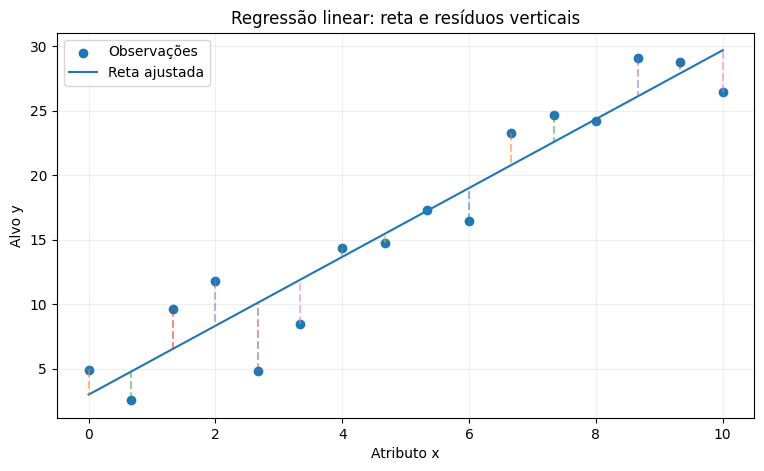

Inclinação estimada: 2.67; intercepto: 2.98


In [ ]:
# Demonstração visual com dados artificiais: a reta e os resíduos
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)  # Gerador reprodutível
x_demo = np.linspace(0, 10, 16)
y_demo = 4 + 2.5*x_demo + rng.normal(0, 3, len(x_demo))
coef_demo = np.polyfit(x_demo, y_demo, deg=1)  # Ajusta uma reta por mínimos quadrados
y_prev_demo = np.polyval(coef_demo, x_demo)

plt.figure(figsize=(9, 5))
plt.scatter(x_demo, y_demo, label='Observações')
plt.plot(x_demo, y_prev_demo, label='Reta ajustada')
for x, observado, previsto in zip(x_demo, y_demo, y_prev_demo):
    plt.plot([x, x], [observado, previsto], '--', alpha=0.5)
plt.xlabel('Atributo x')
plt.ylabel('Alvo y')
plt.title('Regressão linear: reta e resíduos verticais')
plt.legend()
plt.grid(alpha=0.2)
plt.show()
print(f'Inclinação estimada: {coef_demo[0]:.2f}; intercepto: {coef_demo[1]:.2f}')

**Observe:** os segmentos tracejados são os resíduos. Se a reta fosse deslocada ou inclinada de outra forma, a soma dos quadrados desses segmentos mudaria. **Pergunta:** por que um erro de 10 unidades pesa mais que dois erros de 5 unidades no OLS?

# Módulo 2 — Conhecendo o dataset

O `load_diabetes` possui **442 observações**, **10 atributos numéricos** e um alvo quantitativo. Os atributos fornecidos por padrão já são centralizados e escalados por uma transformação própria do dataset; **não** são medidas clínicas em unidades originais. O atributo `bmi`, por exemplo, não está expresso diretamente em kg/m².

Para esta aula, o alvo será usado apenas como variável didática. Não atribua interpretações clínicas individuais a coeficientes sem validação adicional.

In [ ]:
# Bibliotecas principais — disponíveis normalmente no Google Colab
import pandas as pd
import sklearn
from sklearn.datasets import load_diabetes

print('Versão do scikit-learn:', sklearn.__version__)
dados = load_diabetes(as_frame=True)
X = dados.data.copy()  # Somente atributos preditores
y = dados.target.copy()  # Alvo contínuo
print('Dimensão de X:', X.shape)
print('Dimensão de y:', y.shape)
print('Atributos:', list(X.columns))
display(X.head())

Versão do scikit-learn: 1.6.1
Dimensão de X: (442, 10)
Dimensão de y: (442,)
Atributos: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [ ]:
# Inspecionando o alvo e possíveis valores ausentes
print('Descrição estatística do alvo:')
display(y.describe().to_frame('progressao'))
print('Valores ausentes por atributo:')
display(X.isna().sum().to_frame('ausentes'))
print('Valores ausentes no alvo:', y.isna().sum())

Descrição estatística do alvo:


,progressao
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


Valores ausentes por atributo:


,ausentes
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Valores ausentes no alvo: 0


**Interpretação:** o modelo não deve receber `y` como entrada: isso seria **vazamento de dados (data leakage)**. A tarefa é estimar `y` a partir dos atributos disponíveis.

# Módulo 3 — Análise exploratória

Antes de treinar, observe distribuição, possíveis relações e escalas. Um gráfico pode sugerir uma tendência, mas não substitui avaliação fora da amostra.

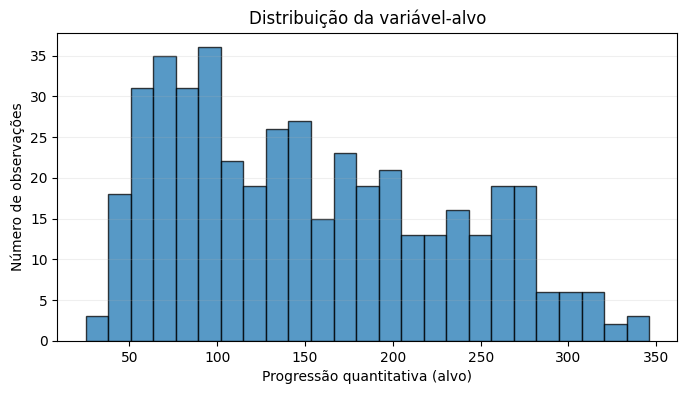

In [ ]:
# Histograma do alvo: distribuição dos valores que desejamos prever
plt.figure(figsize=(8, 4))
plt.hist(y, bins=25, edgecolor='black', alpha=0.75)
plt.xlabel('Progressão quantitativa (alvo)')
plt.ylabel('Número de observações')
plt.title('Distribuição da variável-alvo')
plt.grid(axis='y', alpha=0.2)
plt.show()

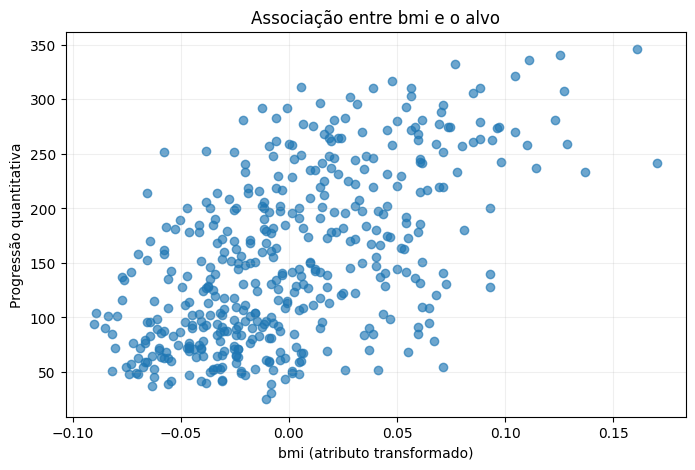

Correlação de Pearson: 0.586


In [ ]:
# Dispersão entre BMI transformado e alvo
plt.figure(figsize=(8, 5))
plt.scatter(X['bmi'], y, alpha=0.65)
plt.xlabel('bmi (atributo transformado)')
plt.ylabel('Progressão quantitativa')
plt.title('Associação entre bmi e o alvo')
plt.grid(alpha=0.2)
plt.show()
print('Correlação de Pearson:', round(X['bmi'].corr(y), 3))

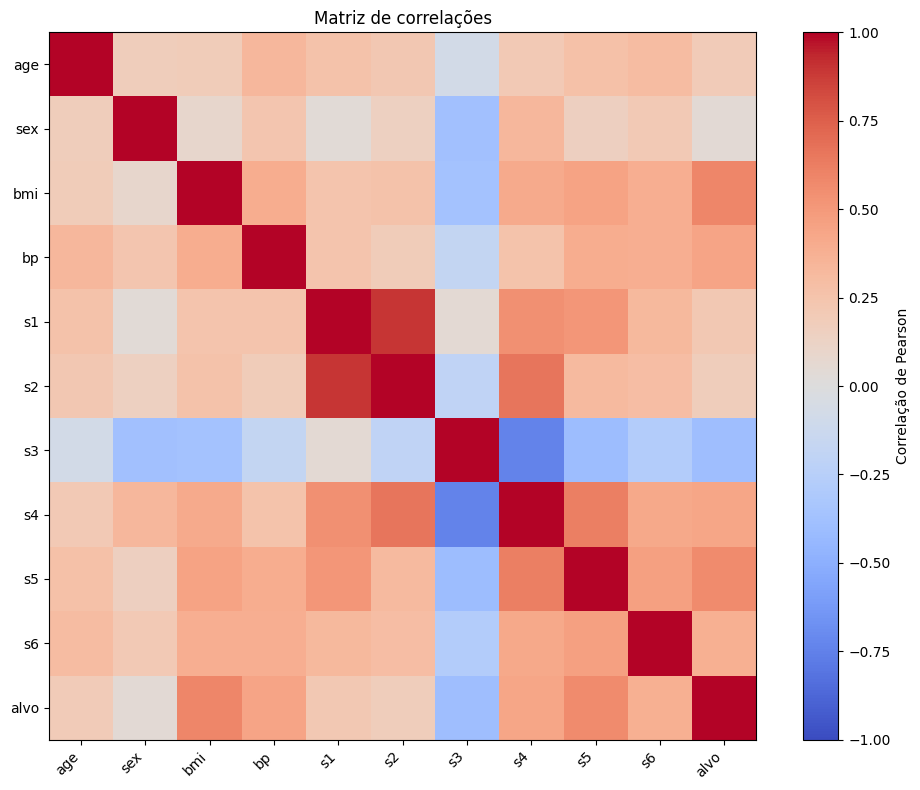

In [ ]:
# Matriz de correlação: relação linear entre atributos e alvo
base_exploratoria = X.copy()
base_exploratoria['alvo'] = y
correlacoes = base_exploratoria.corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(correlacoes, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(correlacoes.columns)), correlacoes.columns, rotation=45, ha='right')
ax.set_yticks(range(len(correlacoes.index)), correlacoes.index)
fig.colorbar(im, ax=ax, label='Correlação de Pearson')
ax.set_title('Matriz de correlações')
plt.tight_layout()
plt.show()

**Para discutir:** correlação entre dois preditores pode indicar **multicolinearidade**, tornando alguns coeficientes instáveis. Correlação alta com o alvo não implica que o atributo seja causal nem que seja suficiente para boa previsão.

# Módulo 4 — Regressão linear simples

Começaremos com apenas `bmi`. A separação treino/teste será feita **antes** de ajustar o modelo. O conjunto de teste representa observações que não foram usadas para estimar os coeficientes.

Usaremos `random_state=42` para reprodução e `test_size=0.2` para reservar 20% dos exemplos para teste.

In [ ]:
# 1. Selecionar uma única coluna (mantendo DataFrame 2D)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_simples = X[['bmi']]
X_treino_s, X_teste_s, y_treino_s, y_teste_s = train_test_split(
    X_simples, y, test_size=0.20, random_state=42
)
print('Treino:', X_treino_s.shape, '| Teste:', X_teste_s.shape)

Treino: (353, 1) | Teste: (89, 1)


In [ ]:
# 2. Criar e ajustar o modelo APENAS no conjunto de treino
modelo_simples = LinearRegression()
modelo_simples.fit(X_treino_s, y_treino_s)
print('Intercepto:', round(modelo_simples.intercept_, 3))
print('Coeficiente de bmi:', round(modelo_simples.coef_[0], 3))

Intercepto: 152.003
Coeficiente de bmi: 998.578


In [ ]:
# 3. Fazer previsões para exemplos nunca vistos no ajuste
y_prev_s = modelo_simples.predict(X_teste_s)
comparacao_simples = pd.DataFrame({
    'real': y_teste_s.to_numpy(),
    'previsto': y_prev_s,
    'residuo': y_teste_s.to_numpy() - y_prev_s
})
display(comparacao_simples.head(10))

,real,previsto,residuo
0,219.0,145.806227,73.193773
1,70.0,188.857390,-118.857390
2,202.0,147.958785,54.041215
3,230.0,203.925298,26.074702
4,111.0,131.814599,-20.814599
5,84.0,127.509482,-43.509482
6,242.0,322.315998,-80.315998
7,272.0,197.467623,74.532377
8,94.0,61.856458,32.143542
9,96.0,167.331809,-71.331809


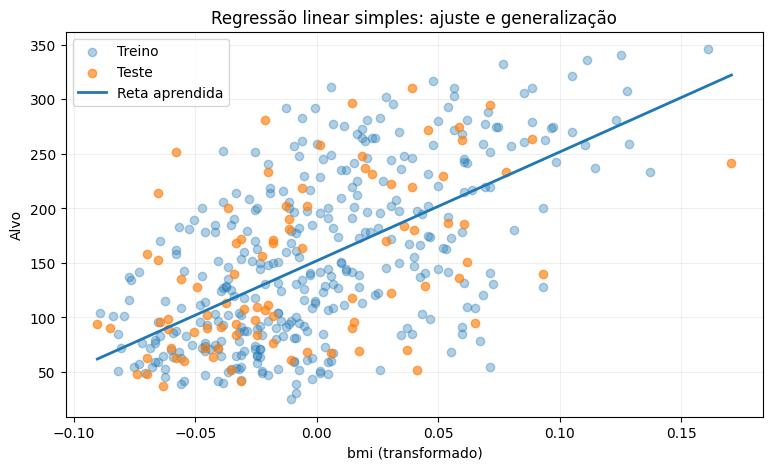

In [ ]:
# 4. Mostrar observações de teste e a reta estimada no treino
x_linha = pd.DataFrame({'bmi': np.linspace(X['bmi'].min(), X['bmi'].max(), 100)})
y_linha = modelo_simples.predict(x_linha)
plt.figure(figsize=(9, 5))
plt.scatter(X_treino_s['bmi'], y_treino_s, alpha=0.35, label='Treino')
plt.scatter(X_teste_s['bmi'], y_teste_s, alpha=0.65, label='Teste')
plt.plot(x_linha['bmi'], y_linha, linewidth=2, label='Reta aprendida')
plt.xlabel('bmi (transformado)')
plt.ylabel('Alvo')
plt.title('Regressão linear simples: ajuste e generalização')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Perguntas:** o coeficiente indica associação positiva ou negativa? Por que a reta não passa por todos os pontos? O que significa o intercepto se `bmi=0` representa uma escala transformada?

# Módulo 5 — Regressão linear múltipla

Agora o modelo utiliza todos os 10 atributos:

$$\hat y=\beta_0+\beta_1x_1+\cdots+\beta_{10}x_{10}.$$

Cada coeficiente representa a variação estimada do alvo quando aquele atributo aumenta uma unidade **mantidos os demais constantes**, dentro do modelo linear. Essa interpretação pode ser frágil quando os atributos são correlacionados.

Para comparação justa, usamos a mesma proporção e a mesma semente de divisão.

In [ ]:
# 1. Dividir os dez atributos em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Treino:', X_treino.shape, '| Teste:', X_teste.shape)

Treino: (353, 10) | Teste: (89, 10)


In [ ]:
# 2. Ajustar regressão múltipla e prever
modelo_multiplo = LinearRegression()
modelo_multiplo.fit(X_treino, y_treino)
y_prev_m = modelo_multiplo.predict(X_teste)
print('Intercepto:', round(modelo_multiplo.intercept_, 2))

Intercepto: 151.35


,coeficiente
s1,-931.488846
sex,-241.964362
age,37.904021
s6,48.670657
s3,163.419983
s4,275.317902
bp,347.703844
s2,518.062277
bmi,542.428759
s5,736.198859


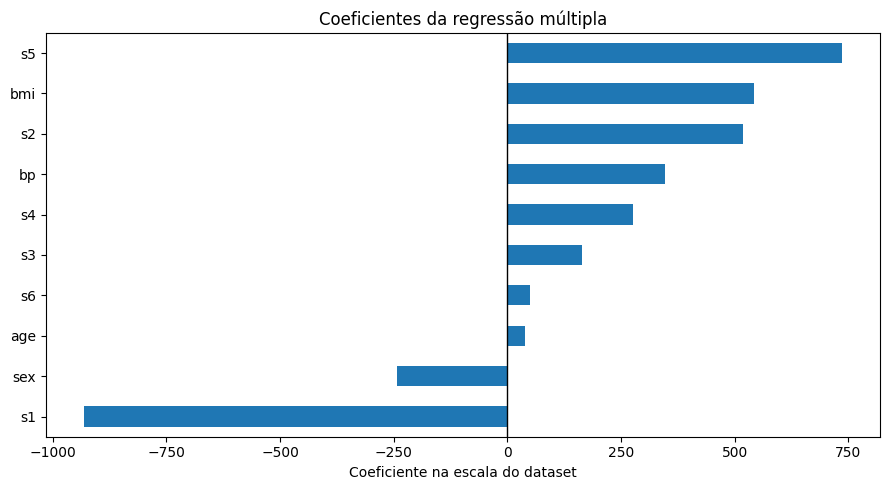

In [ ]:
# 3. Examinar os coeficientes de forma organizada
coeficientes = pd.Series(modelo_multiplo.coef_, index=X.columns, name='coeficiente')
display(coeficientes.sort_values().to_frame())
coeficientes.sort_values().plot(kind='barh', figsize=(9, 5))
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Coeficiente na escala do dataset')
plt.title('Coeficientes da regressão múltipla')
plt.tight_layout()
plt.show()

**Atenção:** um coeficiente com maior magnitude **não** é automaticamente mais importante em termos causais. Escala, correlação entre variáveis e incerteza da estimativa importam.

# Módulo 6 — Métricas e análise de resíduos

As métricas respondem a perguntas diferentes:

- **MAE:** média do erro absoluto. Tem a mesma unidade do alvo.
- **MSE:** média do erro ao quadrado. Penaliza erros grandes e fica na unidade ao quadrado.
- **RMSE:** raiz do MSE. Volta à unidade do alvo.
- **R²:** fração da variabilidade explicada em relação ao preditor constante da média, conforme sua definição no conjunto avaliado. Pode ser **negativo** em teste.

$$MAE=\frac{1}{n}\sum |y_i-\hat y_i|$$
$$MSE=\frac{1}{n}\sum (y_i-\hat y_i)^2$$
$$RMSE=\sqrt{MSE}$$
$$R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$$

**Boa prática:** compare também com um modelo trivial (baseline), que prevê a média do alvo de treino.

In [ ]:
# Função reutilizável para avaliar previsões
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

def avaliar(nome, observado, previsto):
    # Converte previsões em métricas com nomes consistentes
    mse = mean_squared_error(observado, previsto)
    return {'modelo': nome,
            'MAE': mean_absolute_error(observado, previsto),
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'R2': r2_score(observado, previsto)}

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_treino, y_treino)
y_prev_base = baseline.predict(X_teste)
resultados = [
    avaliar('Baseline (média)', y_teste, y_prev_base),
    avaliar('Linear simples (bmi)', y_teste_s, y_prev_s),
    avaliar('Linear múltipla', y_teste, y_prev_m)
]
display(pd.DataFrame(resultados).round(3))

,modelo,MAE,MSE,RMSE,R2
0,Baseline (média),64.006,5361.533,73.222,-0.012
1,Linear simples (bmi),52.260,4061.826,63.732,0.233
2,Linear múltipla,42.794,2900.194,53.853,0.453


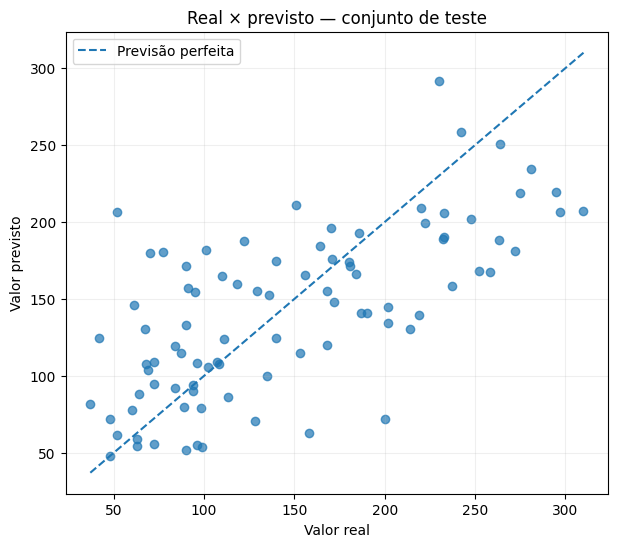

In [ ]:
# Dispersão entre valores reais e previstos (modelo múltiplo)
plt.figure(figsize=(7, 6))
plt.scatter(y_teste, y_prev_m, alpha=0.7)
limites = [min(y_teste.min(), y_prev_m.min()), max(y_teste.max(), y_prev_m.max())]
plt.plot(limites, limites, '--', label='Previsão perfeita')
plt.xlabel('Valor real')
plt.ylabel('Valor previsto')
plt.title('Real × previsto — conjunto de teste')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

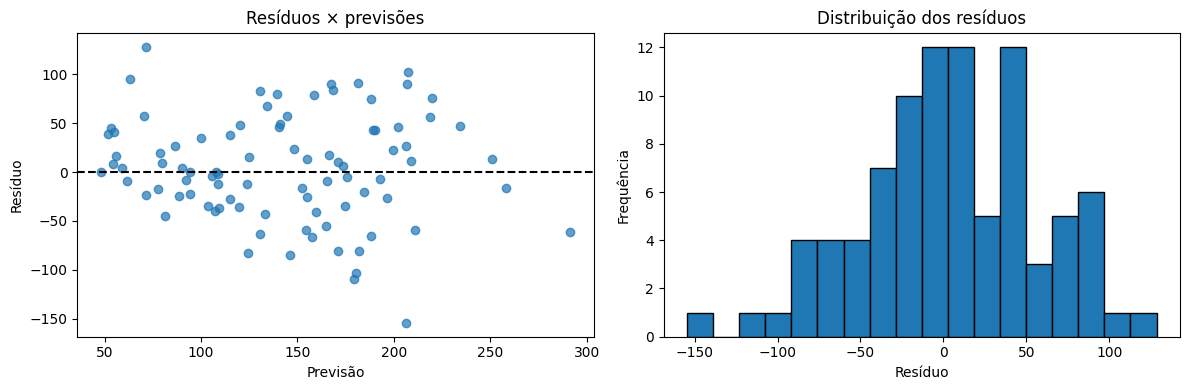

In [ ]:
# Resíduos: observar padrões e possíveis violações do modelo
residuos = y_teste.to_numpy() - y_prev_m
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].scatter(y_prev_m, residuos, alpha=0.7)
eixos[0].axhline(0, linestyle='--', color='black')
eixos[0].set(xlabel='Previsão', ylabel='Resíduo', title='Resíduos × previsões')
eixos[1].hist(residuos, bins=18, edgecolor='black')
eixos[1].set(xlabel='Resíduo', ylabel='Frequência', title='Distribuição dos resíduos')
plt.tight_layout()
plt.show()

**Interpretação crítica:** resíduos com curvatura podem sugerir não linearidade; dispersão que aumenta com a previsão pode sugerir heterocedasticidade; valores extremos merecem investigação. Um histograma aparentemente simétrico não prova normalidade. Esses gráficos são diagnósticos exploratórios, não testes conclusivos.

# Módulo 7 — Generalização, validação cruzada e overfitting

Um bom desempenho em treino não garante bom desempenho em dados novos. **Overfitting** ocorre quando o modelo se adapta excessivamente ao treino; **underfitting** ocorre quando não captura relações importantes.

A **validação cruzada K-Fold** divide o conjunto de desenvolvimento em partes: em cada rodada, ajusta em K−1 partes e valida na parte restante. O teste final deve ficar reservado até a seleção dos modelos.

**Neste notebook didático**, já visualizamos o teste para aprender métricas. Em uma pesquisa real, planeje os modelos e hiperparâmetros usando apenas treino/validação, e consulte o teste uma única vez no fim.

In [ ]:
# Validação cruzada apenas sobre o conjunto de treino
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)
metricas_cv = {'mae': 'neg_mean_absolute_error', 'r2': 'r2'}
cv_resultado = cross_validate(LinearRegression(), X_treino, y_treino,
                              cv=cv, scoring=metricas_cv)
maes = -cv_resultado['test_mae']  # sklearn usa sinal negativo para erros em scoring
r2s = cv_resultado['test_r2']
print('MAE por fold:', np.round(maes, 2))
print(f'MAE médio: {maes.mean():.2f} ± {maes.std():.2f}')
print(f'R² médio: {r2s.mean():.3f} ± {r2s.std():.3f}')

MAE por fold: [44.59 48.28 42.93 44.3  45.15]
MAE médio: 45.05 ± 1.77
R² médio: 0.480 ± 0.041


In [ ]:
# Comparação de erro de treino e teste: diagnóstico introdutório
prev_treino = modelo_multiplo.predict(X_treino)
quadro = pd.DataFrame([
    avaliar('Treino', y_treino, prev_treino),
    avaliar('Teste', y_teste, y_prev_m)
])
display(quadro[['modelo', 'MAE', 'RMSE', 'R2']].round(3))

,modelo,MAE,RMSE,R2
0,Treino,43.484,53.559,0.528
1,Teste,42.794,53.853,0.453


**Pergunta:** se um modelo obtém R² muito alto no treino e baixo no teste, o que isso sugere? Por que não devemos selecionar repetidamente hiperparâmetros observando o desempenho do teste?

# Módulo 8 — Regularização e não linearidade

## Ridge e Lasso

A regressão linear comum minimiza o erro quadrático. **Ridge** adiciona uma penalidade proporcional à soma dos quadrados dos coeficientes (L2). **Lasso** utiliza soma dos valores absolutos (L1), podendo reduzir coeficientes a zero.

- Ridge: útil para estabilizar estimativas com atributos correlacionados.
- Lasso: pode realizar seleção implícita de atributos.
- `alpha`: controla a intensidade da penalização; valores maiores costumam gerar maior contração.

Para evitar vazamento, colocamos `StandardScaler` e modelo em um **Pipeline**: a padronização é ajustada somente aos dados de treino em cada fold.

In [ ]:
# Comparar modelos com validação cruzada no conjunto de treino
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso

candidatos = {
    'Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge alpha=1': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Lasso alpha=1': make_pipeline(StandardScaler(), Lasso(alpha=1.0, max_iter=20000))
}
linhas = []
for nome, estimador in candidatos.items():
    resultado = cross_validate(estimador, X_treino, y_treino,
                               cv=cv, scoring=metricas_cv)
    linhas.append({'modelo': nome,
                   'MAE_CV': -resultado['test_mae'].mean(),
                   'R2_CV': resultado['test_r2'].mean()})
tabela_cv = pd.DataFrame(linhas).sort_values('MAE_CV')
display(tabela_cv.round(3))

,modelo,MAE_CV,R2_CV
1,Ridge alpha=1,44.999,0.481
0,Linear,45.048,0.480
2,Lasso alpha=1,45.136,0.481


## Regressão polinomial

Uma relação pode ser curva. `PolynomialFeatures(degree=2)` cria termos como $x^2$ e interações, permitindo que um modelo linear em seus coeficientes represente relações não lineares nos atributos.

**Cuidado:** aumentar o grau aumenta a complexidade e pode produzir overfitting. Usaremos apenas `bmi` para visualizar facilmente a diferença.

,modelo,MAE,MSE,RMSE,R2
0,Linear simples,52.260,4061.826,63.732,0.233
1,Polinomial grau 2,52.384,4085.025,63.914,0.229


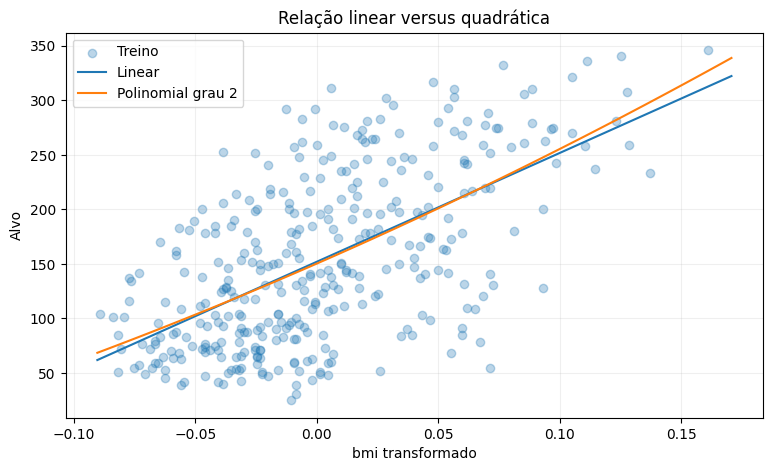

In [ ]:
# Comparação entre reta e curva quadrática usando o mesmo treino simples
from sklearn.preprocessing import PolynomialFeatures

modelo_polinomial = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
modelo_polinomial.fit(X_treino_s, y_treino_s)
prev_poli = modelo_polinomial.predict(X_teste_s)

display(pd.DataFrame([
    avaliar('Linear simples', y_teste_s, y_prev_s),
    avaliar('Polinomial grau 2', y_teste_s, prev_poli)
]).round(3))

plt.figure(figsize=(9, 5))
plt.scatter(X_treino_s['bmi'], y_treino_s, alpha=0.3, label='Treino')
plt.plot(x_linha['bmi'], modelo_simples.predict(x_linha), label='Linear')
plt.plot(x_linha['bmi'], modelo_polinomial.predict(x_linha), label='Polinomial grau 2')
plt.xlabel('bmi transformado')
plt.ylabel('Alvo')
plt.title('Relação linear versus quadrática')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Escolhendo hiperparâmetros com validação cruzada

O `GridSearchCV` testa valores de `alpha` usando **somente o treino**. O melhor estimador será reajustado sobre todo o conjunto de treino. Depois, avaliamos uma vez no teste.

In [ ]:
# Seleção de alpha sem consultar o teste durante a busca
from sklearn.model_selection import GridSearchCV

pipeline_ridge = make_pipeline(StandardScaler(), Ridge())
busca = GridSearchCV(
    pipeline_ridge,
    param_grid={'ridge__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    scoring='neg_mean_absolute_error',
    cv=cv,
    n_jobs=-1
)
busca.fit(X_treino, y_treino)
print('Melhor alpha (por MAE de validação):', busca.best_params_['ridge__alpha'])
print('MAE médio de validação:', round(-busca.best_score_, 2))

Melhor alpha (por MAE de validação): 1
MAE médio de validação: 45.0


In [ ]:
# Avaliação final do Ridge selecionado
prev_ridge = busca.predict(X_teste)
display(pd.DataFrame([
    avaliar('Baseline', y_teste, y_prev_base),
    avaliar('Linear múltipla', y_teste, y_prev_m),
    avaliar('Ridge ajustado por CV', y_teste, prev_ridge)
]).round(3))

,modelo,MAE,MSE,RMSE,R2
0,Baseline,64.006,5361.533,73.222,-0.012
1,Linear múltipla,42.794,2900.194,53.853,0.453
2,Ridge ajustado por CV,42.812,2892.015,53.777,0.454


## Síntese conceitual

1. Defina o problema e identifique a variável-alvo contínua.
2. Separe os dados antes de ajustar transformações.
3. Estabeleça um baseline.
4. Ajuste um modelo simples e interprete seus coeficientes com cautela.
5. Compare erros em validação cruzada.
6. Use `Pipeline` para evitar vazamento.
7. Escolha hiperparâmetros sem olhar o teste.
8. Analise resíduos, generalização e limitações.
9. Faça avaliação final em dados reservados.

**Nota científica:** o dataset é pequeno; os resultados dependem da divisão e não autorizam uso clínico. Para dados de pacientes repetidos, séries temporais ou centros distintos, a estratégia de validação deve respeitar grupos, tempo ou instituição.

# Módulo 9 — Exercício final (10 pontos)

**Instruções aos estudantes:** responda em células Markdown, execute os blocos solicitados e justifique as conclusões. Não basta informar qual modelo tem o maior R². Use somente o conjunto de treino na seleção de hiperparâmetros. Entregue o `.ipynb` com todas as células executadas, gráficos e respostas.

### Questão 1 — Fundamentos (1,0 ponto)
Explique, com suas palavras, a diferença entre regressão, classificação e clustering. Dê um exemplo biomédico de cada um.

### Questão 2 — Coeficientes (1,0 ponto)
Explique o significado do intercepto e do coeficiente de `bmi` na regressão simples. Por que não devemos interpretá-los como efeitos causais?

### Questão 3 — Métricas (1,0 ponto)
Explique MAE, RMSE e R². Qual métrica penaliza mais fortemente erros grandes? Um R² negativo é possível?

### Questão 4 — Exploração (1,0 ponto)
Escolha um atributo diferente de `bmi`. Faça um gráfico de dispersão com o alvo e descreva a relação observada.

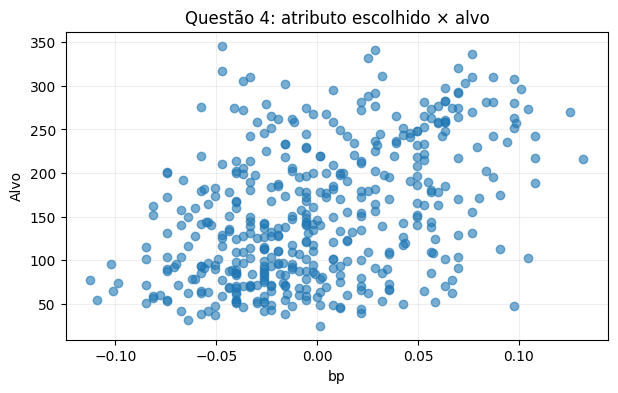

In [ ]:
# QUESTÃO 4 — Complete o nome do atributo e execute
atributo_escolhido = 'bp'  # TROQUE por outro atributo, se desejar
plt.figure(figsize=(7, 4))
plt.scatter(X[atributo_escolhido], y, alpha=0.6)
plt.xlabel(atributo_escolhido)
plt.ylabel('Alvo')
plt.title('Questão 4: atributo escolhido × alvo')
plt.grid(alpha=0.2)
plt.show()
# RESPOSTA EM MARKDOWN: descreva tendência, dispersão e limitações.

### Questão 5 — Modelo simples alternativo (1,0 ponto)
Treine uma regressão simples usando o atributo da Questão 4. Compare MAE e R² com o modelo que utilizou `bmi`. Justifique qual generalizou melhor nesta divisão.

In [ ]:
# QUESTÃO 5 — Código guiado; complete a interpretação em Markdown
X_alternativo = X[[atributo_escolhido]]
Xa_treino, Xa_teste, ya_treino, ya_teste = train_test_split(
    X_alternativo, y, test_size=0.20, random_state=42
)
modelo_alternativo = LinearRegression()
modelo_alternativo.fit(Xa_treino, ya_treino)
prev_alternativa = modelo_alternativo.predict(Xa_teste)
display(pd.DataFrame([
    avaliar('bmi', y_teste_s, y_prev_s),
    avaliar(atributo_escolhido, ya_teste, prev_alternativa)
]).round(3))

,modelo,MAE,MSE,RMSE,R2
0,bmi,52.260,4061.826,63.732,0.233
1,bp,57.224,4379.390,66.177,0.173


### Questão 6 — Regularização (1,5 ponto)
Compare Ridge com `alpha=0.1`, `1`, `10` e `100` por validação cruzada no treino. Qual obteve o menor MAE médio? O resultado é estável? Discuta a influência de `alpha`.

In [ ]:
# QUESTÃO 6 — Complete o laço e examine os resultados
resultados_alpha = []
for alpha in [0.1, 1, 10, 100]:
    modelo = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    notas = cross_validate(modelo, X_treino, y_treino, cv=cv,
                           scoring='neg_mean_absolute_error')
    resultados_alpha.append({'alpha': alpha,
                             'MAE_CV': -notas['test_score'].mean(),
                             'desvio_CV': (-notas['test_score']).std()})
display(pd.DataFrame(resultados_alpha).round(3))
# RESPOSTA EM MARKDOWN: compare médias e variabilidade entre folds.

,alpha,MAE_CV,desvio_CV
0,0.1,45.041,1.777
1,1.0,44.999,1.808
2,10.0,45.060,1.951
3,100.0,46.047,2.869


### Questão 7 — Resíduos (1,0 ponto)
A partir do gráfico de resíduos da regressão múltipla, descreva se existe um padrão evidente, se há erros extremos e quais limitações isso sugere.

### Questão 8 — Pensamento crítico (1,0 ponto)
Por que escolher repetidamente modelos pelo melhor resultado no teste causa viés? Explique como a validação cruzada e um teste final reservado reduzem esse problema.

### Questão 9 — Mini-relatório (1,5 ponto)
Produza um relatório de **200 a 350 palavras** com: objetivo, dataset, divisão dos dados, modelos comparados, métricas, melhor resultado observado, limitações e conclusão. Não afirme que o modelo está pronto para uso clínico.

## Critérios de correção
- Fundamentação conceitual e rigor: **3,0 pontos**
- Execução e organização dos experimentos: **3,0 pontos**
- Interpretação crítica de métricas e gráficos: **2,5 pontos**
- Qualidade do mini-relatório: **1,5 ponto**

> **Observação:** as questões já indicam pontuações individuais que somam 10,0; os critérios acima descrevem dimensões transversais de avaliação, não pontos adicionais.

## Espaço para respostas

**Q1:**

A regressão é usada quando a gente quer prever um valor numérico, por exemplo estimar a glicemia de um paciente a partir dos resultados dos exames. A classificação prevê uma categoria, como dizer se um tumor é benigno ou maligno. Já o clustering não tem uma resposta certa pra aprender, ele só junta os dados parecidos em grupos. Um exemplo seria separar pacientes em perfis semelhantes sem saber o diagnóstico de cada um.

**Q2:**

O intercepto deu mais ou menos 152 e é o valor previsto quando o bmi vale zero. Como os atributos do dataset já vêm centralizados, bmi igual a zero seria um bmi médio, então o intercepto fica perto da média do alvo. O coeficiente do bmi deu cerca de 998,6. Como ele é positivo, quanto maior o bmi maior a progressão prevista. Ele é um número alto porque o bmi está numa escala transformada e não em kg/m². Não dá pra dizer que é um efeito causal porque o modelo só encontra uma associação nos dados. Pode ter outras variáveis que não entraram no modelo explicando essa relação, e os dados não vêm de um experimento controlado.

**Q3:**

O MAE é a média dos erros em valor absoluto e fica na mesma unidade do alvo. O RMSE é a raiz da média dos erros ao quadrado e também volta pra unidade do alvo. O R² mostra quanto da variação do alvo o modelo consegue explicar, comparando com um modelo que sempre chuta a média. Quem penaliza mais os erros grandes é o RMSE, porque eleva os erros ao quadrado antes de fazer a média. O R² pode sim ser negativo, isso acontece quando o modelo vai pior que simplesmente prever a média. No teste o próprio baseline deu R² de -0,012.

**Q4:**

Usei o atributo bp. No gráfico dá pra ver uma tendência positiva, quando o bp aumenta o alvo também tende a aumentar, mas a relação é de fraca pra moderada (correlação de 0,44). Os pontos estão bem espalhados, então só o bp não seria suficiente pra prever bem. Também tem a limitação de ser uma escala transformada e de a gente estar olhando só a relação linear, sem nenhuma conclusão sobre causa.

**Q5:**

Com o bmi o modelo teve MAE de 52,26 e R² de 0,233. Com o bp o MAE foi 57,22 e o R² 0,173. Então nessa divisão o bmi generalizou melhor, porque errou menos e explicou mais da variação. Mesmo assim os dois sozinhos explicam pouco, e com outra divisão dos dados o resultado poderia mudar.

**Q6:**

Os resultados da validação cruzada foram: alpha 0,1 com MAE de 45,04 (desvio 1,78), alpha 1 com 45,00 (desvio 1,81), alpha 10 com 45,06 (desvio 1,95) e alpha 100 com 46,05 (desvio 2,87). O menor MAE foi com alpha 1, mas a diferença entre 0,1, 1 e 10 é muito pequena, menor até que o desvio entre os folds, então na prática eles empatam. Com alpha 100 a penalização fica forte demais, os coeficientes encolhem muito, o modelo perde informação e o erro aumenta, além de ficar mais instável entre os folds. Nesse dataset regularizar pouco quase não muda nada, já que a regressão linear sem regularização teve MAE de validação de 45,05.

**Q7:**

No gráfico de resíduos não aparece um padrão muito claro, tipo uma curva, e os pontos ficam espalhados em volta do zero. Mas existem alguns erros bem grandes, o maior passa de 150 e outros ficam acima de 100. Também parece que a dispersão aumenta um pouco quando a previsão é maior. Isso indica que o modelo linear não capta tudo, pode ter relações não lineares, variáveis que ficaram de fora ou alguns outliers.

**Q8:**

Se a gente testa vários modelos e escolhe sempre o que foi melhor no teste, acaba ajustando a escolha pra aquele conjunto específico. Aí o teste deixa de representar dados novos e o resultado final fica otimista demais. Com a validação cruzada a escolha do modelo e dos hiperparâmetros é feita só com o treino, dividido em folds, e o teste fica guardado pra ser usado uma vez só no final. Assim a avaliação final fica mais próxima do desempenho real.

**Q9 - Mini-relatório:**

O objetivo do trabalho foi prever a progressão da diabetes depois de um ano usando modelos de regressão do scikit-learn. O dataset usado foi o load_diabetes, que tem 442 pacientes, 10 atributos já padronizados e um alvo numérico, sem valores ausentes.

Os dados foram divididos em 80% para treino e 20% para teste, com random_state=42. Para escolher os hiperparâmetros usei validação cruzada K-Fold com 5 folds, sempre só no conjunto de treino.

Comparei um baseline que prevê a média, regressões lineares simples com bmi e com bp, uma regressão polinomial de grau 2 com bmi, a regressão linear múltipla e o Ridge com alpha escolhido pelo GridSearchCV.

No teste, o baseline teve MAE de 64,0 e R² de -0,01. A regressão simples com bmi chegou a MAE de 52,3 e R² de 0,23, e a polinomial não trouxe melhora (R² de 0,23). A regressão múltipla teve MAE de 42,8 e R² de 0,45, e o Ridge com alpha 1 ficou praticamente igual. Os resultados de treino e teste foram parecidos (R² de 0,53 e 0,45), então não parece ter overfitting forte.

Os melhores resultados foram da regressão múltipla e do Ridge, que ficaram empatados e bem acima do baseline e dos modelos com um atributo só.

Como limitações, o dataset é pequeno, os resultados dependem da divisão e o modelo explica menos da metade da variação do alvo. Também aparecem erros grandes nos resíduos, os atributos estão numa escala transformada e os coeficientes não mostram causa.

Concluindo, usar vários atributos melhora bastante a previsão, mas o modelo serve só para estudo e não pode ser usado em decisões clínicas.


# Referências e leituras recomendadas

- [Scikit-learn — Linear Models](https://scikit-learn.org/stable/modules/linear_model.html)
- [Scikit-learn — Model Evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Scikit-learn — Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Scikit-learn — Diabetes dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)
- [Scikit-learn — Pipelines](https://scikit-learn.org/stable/modules/compose.html#pipeline)

**Fim da aula.**